In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
def RFL_model(parameters, states, dt): 
    #ribosome flow model, original equations with the simplification that all elongation rates are homogeneous β
    
    #states are ocupation probabilities
    
    if states.shape[0] != parameters['l']: 
        raise ValueError('Number of states incompatible with gene length')
    
    
    new_states = np.zeros(states.shape)
    new_states[0] = states[0] + (parameters['α']*(1 - states[0]) - parameters['β']* states[0] * (1-states[1]))*dt
    for n in range(1, parameters['l']-1): 
        new_states[n] = states[n]+ (parameters['β']* states[n-1] * (1- states[n]) - parameters['β']* states[n] * (1-states[n+1]))*dt
    new_states[-1] = states[-1] + (parameters['β']* (states[-2]* (1-states[-1]) - states[-1]))*dt
    
    return new_states

        
def simulation_wrapper(state0, params, update, sim_time, dt): 
    #euler method to see behaviour quickly
    
    states = np.zeros([int(sim_time/dt)+1, state0.shape[0]])
    states[0,:] = state0
    
    for t in range(int(sim_time/dt)): 
        states[t+1] = update(params, states[t], dt)
        
    return states

In [3]:
α = 0.5 #ribosomal flow (initiation)
β = .5 #homogeneous elongation or transfer rates
l = 25 #in codons

parameters = dict()
parameters['α'] = α
parameters['β'] = β
parameters['l'] = l

sim_time = 800
dt = 0.001


init_states = np.zeros([l])

sim_res = simulation_wrapper(init_states, parameters, RFL_model,sim_time, dt)

l = 50
parameters['l'] = l
init_states = np.zeros([l])
sim_res_long = simulation_wrapper(init_states, parameters, RFL_model,sim_time, dt)

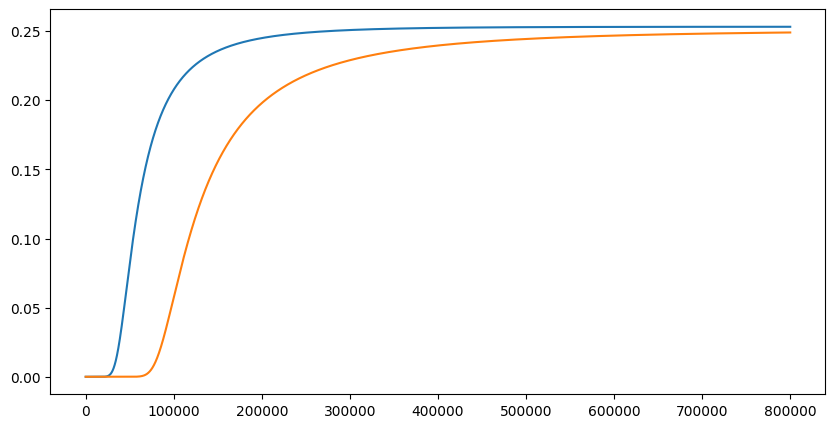

In [4]:
#plot first results, just seeing how it looks: 
#-1 is the produced protein at that point or rather the occupation for the last codon group

fig, ax = plt.subplots(1,1, figsize = (10,5))
ax.plot(sim_res[:,-1])
ax.plot(sim_res_long[:,-1])
plt.show()

In [5]:
#length dependence

Ls = np.arange(2,51, 1)
res = np.zeros(Ls.shape)
for l in range(Ls.shape[0]): 
    parameters['l'] = Ls[l]
    init_states = np.zeros([Ls[l]])
    sim_res = simulation_wrapper(init_states, parameters, RFL_model,sim_time, dt)
    res[l] = sim_res[-1,-1] #looking at the occupation probability of the last codon group


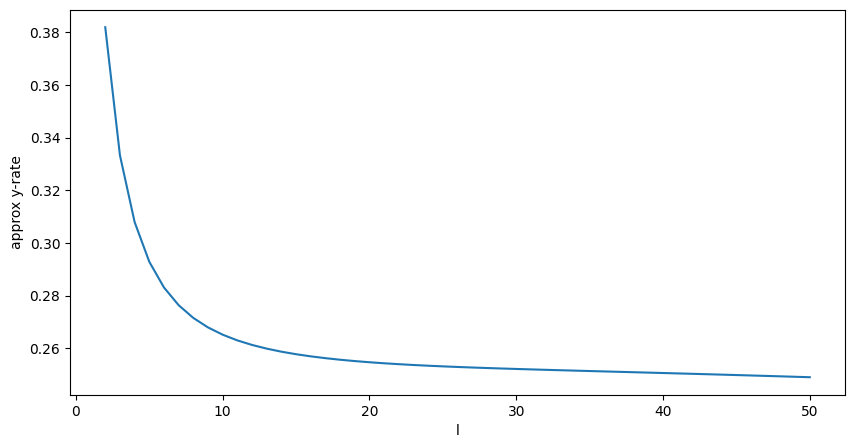

In [6]:
fig, ax = plt.subplots(1,1, figsize = (10,5))
ax.plot(Ls, res) #think about how to do this more reasonable
ax.set_xlabel('l')
ax.set_ylabel('approx y-rate')
plt.show()